RITHESH P -24BAD098

In [22]:
#Part A – Dataset preparation and text preprocessing
#– Install required libraries
!pip install -q transformers datasets accelerate scikit-learn torch pandas matplotlib

In [23]:
import torch
import numpy as np0
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("Roll Number: 24BAD098")
print("PyTorch Version:", torch.__version__)

Roll Number: 24BAD098
PyTorch Version: 2.11.0+cpu


In [24]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("IMDB Dataset.csv")

print("Dataset Loaded Successfully")
print(df.head())

Saving IMDB Dataset.csv to IMDB Dataset (1).csv
Dataset Loaded Successfully
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [25]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nSample Review:")
print(df["review"][0])

Dataset Shape: (50000, 2)

Columns:
Index(['review', 'sentiment'], dtype='object')

Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sample Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agen

In [26]:
import re

df = df.dropna()

df["review"] = df["review"].astype(str)

df["review"] = df["review"].apply(
    lambda x: re.sub(r"<.*?>", " ", x)
)

df["review"] = df["review"].str.strip()

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

df = df.dropna(subset=["label"])

df["label"] = df["label"].astype(int)

print(df.head())
print("\nCleaned Dataset Shape:", df.shape)

                                              review sentiment  label
0  One of the other reviewers has mentioned that ...  positive      1
1  A wonderful little production.   The filming t...  positive      1
2  I thought this was a wonderful way to spend ti...  positive      1
3  Basically there's a family where a little boy ...  negative      0
4  Petter Mattei's "Love in the Time of Money" is...  positive      1

Cleaned Dataset Shape: (50000, 3)


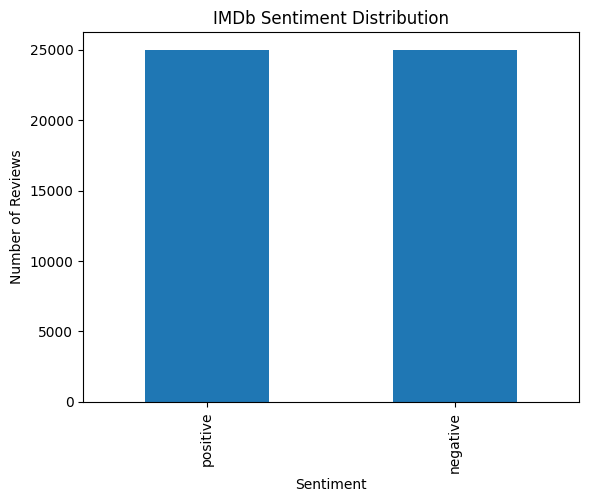

In [27]:
df["sentiment"].value_counts().plot(
    kind="bar",
    title="IMDb Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [29]:
from sklearn.model_selection import train_test_split

# Safely extract a stratified 2,500-sample subset using train_test_split
_, df_subset = train_test_split(
    df,
    test_size=2500,
    stratify=df["label"],
    random_state=42
)

# Split this stratified subset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    df_subset["review"],
    df_subset["label"],
    test_size=0.2,
    random_state=42,
    stratify=df_subset["label"]
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 2000
Testing Samples: 500


In [30]:
# Use DistilBERT (faster, smaller and lighter than standard BERT)
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("DistilBERT Tokenizer Loaded Successfully")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT Tokenizer Loaded Successfully


In [31]:
train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("Training Data Tokenized")
print("Testing Data Tokenized")

Training Data Tokenized
Testing Data Tokenized


In [32]:
class IMDbDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):
        return len(self.labels)


train_dataset = IMDbDataset(
    train_encodings,
    y_train
)

test_dataset = IMDbDataset(
    test_encodings,
    y_test
)

print("PyTorch Dataset Prepared Successfully")

PyTorch Dataset Prepared Successfully


In [33]:
#Part B – Fine-tuning DistilBERT for text classification
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT Model Loaded Successfully")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT Model Loaded Successfully


In [34]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_recall_fscore_support

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation Metrics Defined")

Evaluation Metrics Defined


In [35]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16, # Increased batch size for faster processing
    per_device_eval_batch_size=16,
    num_train_epochs=1,            # Reduced to 1 epoch for speed
    weight_decay=0.01,
    report_to="none"
)

print("Fast Training Parameters Configured")

Fast Training Parameters Configured


In [36]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("Trainer Created Successfully")

Trainer Created Successfully


In [37]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.396093,0.832000,0.812030,0.864000,0.837209


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=125, training_loss=0.4833488464355469, metrics={'train_runtime': 1541.4544, 'train_samples_per_second': 1.297, 'train_steps_per_second': 0.081, 'total_flos': 66233699328000.0, 'train_loss': 0.4833488464355469, 'epoch': 1.0})

In [38]:
results = trainer.evaluate()

print("BERT Model Evaluation")

for key, value in results.items():
    print(key, ":", value)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.396093,1,0.832000,0.812030,0.864000,0.837209


BERT Model Evaluation
eval_loss : 0.3960933983325958
eval_accuracy : 0.832
eval_precision : 0.8120300751879699
eval_recall : 0.864
eval_f1 : 0.8372093023255814


In [39]:
trainer.save_model("bert_sentiment_model")

tokenizer.save_pretrained("bert_sentiment_model")

print("BERT Model Saved Successfully")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Model Saved Successfully


In [40]:
#Part C – Implementing sequence-to-sequence text generation using T5
from transformers import T5ForConditionalGeneration

t5_tokenizer = AutoTokenizer.from_pretrained(
    "google-t5/t5-small"
)

t5_model = T5ForConditionalGeneration.from_pretrained(
    "google-t5/t5-small"
)

print("T5 Model Loaded Successfully")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5 Model Loaded Successfully


In [41]:
input_text = df["review"].iloc[0]

print("Original IMDb Review:")
print(input_text)

Original IMDb Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.  The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.  It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.  I would say the main appeal of the show is due to the fact that i

In [42]:
input_prompt = "summarize: " + input_text

inputs = t5_tokenizer(
    input_prompt,
    return_tensors="pt",
    max_length=512,
    truncation=True
)

print("Input Text Tokenized Successfully")

Input Text Tokenized Successfully


In [43]:
outputs = t5_model.generate(
    inputs["input_ids"],
    max_length=100,
    num_beams=4,
    early_stopping=True
)

generated_text = t5_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Original Review:")
print(input_text)

print("\nGenerated Summary:")
print(generated_text)

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.  The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.  It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.  I would say the main appeal of the show is due to the fact that it goe

In [44]:
for i in range(5):

    text = "summarize: " + df["review"].iloc[i]

    inputs = t5_tokenizer(
        text,
        return_tensors="pt",
        max_length=512,
        truncation=True
    )

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=100,
        num_beams=4
    )

    summary = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("\nReview Number:", i + 1)
    print("Original:", df["review"].iloc[i][:300])
    print("Summary:", summary)
    print("-" * 50)


Review Number: 1
Original: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.  The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, thi
Summary: the first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. it is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. it focuses on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards.
--------------------------------------------------

Review Number: 2
Original: A wonderful little production.   The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece.   The actors are extremely well chosen- Mi

In [45]:
input_text = "summarize: " + df["review"].iloc[1]

inputs = t5_tokenizer(
    input_text,
    return_tensors="pt",
    max_length=512,
    truncation=True
)

output1 = t5_model.generate(
    inputs["input_ids"],
    max_length=50,
    num_beams=2
)

output2 = t5_model.generate(
    inputs["input_ids"],
    max_length=100,
    num_beams=4
)

print("Output with max length 50:")
print(t5_tokenizer.decode(output1[0], skip_special_tokens=True))

print("\nOutput with max length 100:")
print(t5_tokenizer.decode(output2[0], skip_special_tokens=True))

Output with max length 50:
the filming technique is very old-time-BBC fashion and gives a comforting sense of realism to the entire piece. the actors are extremely well chosen- Michael Sheen has all the voices down pat too.

Output with max length 100:
the filming technique is very old-time-BBC fashion and gives a comforting sense of realism to the entire piece. the actors are extremely well chosen- Michael Sheen has all the voices down pat too. the realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears.


In [46]:
#Part D – Model testing and output analysis
test_reviews = [
    "This movie was excellent and I really enjoyed it.",
    "This movie was boring and completely disappointing.",
    "The acting was wonderful and the story was amazing.",
    "The film was terrible and I hated it."
]

for review in test_reviews:

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    device = next(trainer.model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = trainer.model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print()

Review: This movie was excellent and I really enjoyed it.
Predicted Sentiment: Positive

Review: This movie was boring and completely disappointing.
Predicted Sentiment: Negative

Review: The acting was wonderful and the story was amazing.
Predicted Sentiment: Positive

Review: The film was terrible and I hated it.
Predicted Sentiment: Negative



In [47]:
for i in range(5):

    review = df["review"].iloc[i]

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    device = next(trainer.model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = trainer.model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()

    actual = "Positive" if df["label"].iloc[i] == 1 else "Negative"
    predicted = "Positive" if prediction == 1 else "Negative"

    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)
    print("-" * 40)

Actual Sentiment: Positive
Predicted Sentiment: Positive
----------------------------------------
Actual Sentiment: Positive
Predicted Sentiment: Positive
----------------------------------------
Actual Sentiment: Positive
Predicted Sentiment: Positive
----------------------------------------
Actual Sentiment: Negative
Predicted Sentiment: Negative
----------------------------------------
Actual Sentiment: Positive
Predicted Sentiment: Positive
----------------------------------------


In [48]:
predictions = trainer.predict(test_dataset)

predicted_labels = np.argmax(
    predictions.predictions,
    axis=1
)

actual_labels = predictions.label_ids

comparison = pd.DataFrame({
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

comparison["Actual"] = comparison["Actual"].map({
    0: "Negative",
    1: "Positive"
})

comparison["Predicted"] = comparison["Predicted"].map({
    0: "Negative",
    1: "Positive"
})

print(comparison.head(20))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


      Actual Predicted
0   Negative  Positive
1   Positive  Positive
2   Positive  Negative
3   Positive  Positive
4   Positive  Positive
5   Negative  Negative
6   Negative  Negative
7   Negative  Negative
8   Negative  Positive
9   Negative  Negative
10  Positive  Positive
11  Negative  Negative
12  Negative  Negative
13  Negative  Negative
14  Negative  Negative
15  Positive  Positive
16  Positive  Positive
17  Negative  Negative
18  Negative  Negative
19  Positive  Positive


In [49]:
from sklearn.metrics import classification_report

print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.85      0.80      0.83       250
    Positive       0.81      0.86      0.84       250

    accuracy                           0.83       500
   macro avg       0.83      0.83      0.83       500
weighted avg       0.83      0.83      0.83       500



In [50]:
results_df = pd.DataFrame({
    "Original Review": [input_text],
    "Generated Summary": [
        t5_tokenizer.decode(
            output2[0],
            skip_special_tokens=True
        )
    ]
})

results_df.to_csv(
    "IMDB_Text_Generation_24BAD098.csv",
    index=False
)

print(results_df)
print("Generated Results Saved Successfully")

                                     Original Review  \
0  summarize: A wonderful little production.   Th...   

                                   Generated Summary  
0  the filming technique is very old-time-BBC fas...  
Generated Results Saved Successfully


In [51]:
print("EXPERIMENT 9")
print("TEXT CLASSIFICATION AND TEXT GENERATION")

print("\nBERT MODEL")
print("Used for sentiment classification")
print("Classifies reviews into Positive and Negative")

print("\nT5 MODEL")
print("Used for text generation")
print("Generates summaries from IMDb movie reviews")

print("\nExperiment Completed Successfully")

EXPERIMENT 9
TEXT CLASSIFICATION AND TEXT GENERATION

BERT MODEL
Used for sentiment classification
Classifies reviews into Positive and Negative

T5 MODEL
Used for text generation
Generates summaries from IMDb movie reviews

Experiment Completed Successfully
